In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

def find_repo_root(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        if (parent / "studies").is_dir() and (parent / "run_uc2_age_based.py").exists():
            return parent
    return start

REPO_ROOT = find_repo_root(Path.cwd())
print(f"Repo root: {REPO_ROOT}")

def load_standard_eval(folder: Path):
    eval_path = folder / "standard_eval.csv"
    if not eval_path.exists():
        return None
    df = pd.read_csv(eval_path, index_col=0)
    col = "MoD_0" if "MoD_0" in df.columns else df.columns[0]
    def metric(key):
        return df.loc[key, col] if key in df.index else None
    return {
        "scenario": folder.name,
        "service_rate_pct": metric("served online users [%]"),
        "avg_wait_s": metric("waiting time"),
        "median_wait_s": metric("waiting time (median)"),
        "p90_wait_s": metric("waiting time (90% quantile)"),
        "utilization_pct": metric("% fleet utilization"),
        "num_users": metric("number users"),
        "num_travelers": metric("number travelers"),
        "total_vkm": metric("total vkm"),
    }

def load_case_results(results_dir: Path) -> pd.DataFrame:
    if not results_dir.exists():
        return pd.DataFrame()
    rows = []
    for folder in sorted([p for p in results_dir.iterdir() if p.is_dir()]):
        row = load_standard_eval(folder)
        if row:
            rows.append(row)
    return pd.DataFrame(rows)

Repo root: /Users/danieldeutsch/Desktop/code_projects/FleetPy


# Cross-Hypothesis Results Investigation

This notebook loads results directly from the study result folders and summarizes service rate, wait times, and utilization for H1 (Use Case 1), UC2, and UC3.

Run the simulations before executing these cells. Results are expected under:
- studies/klagenfurt_h1_spitzenzeiten_case_study/results
- studies/uc2_age_based/results
- studies/uc3_accessibility/results

,scenario,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,klagenfurt_h1_spitzenzeiten_scenario_1,1.800000,4.555556,6.00,7.100000,1.196620,9.0
1,klagenfurt_h1_spitzenzeiten_scenario_1__trips,1.032258,4.625000,5.25,6.500000,0.857484,8.0
2,klagenfurt_h1_spitzenzeiten_scenario_2,1.800000,4.555556,6.00,7.100000,0.797747,9.0
3,klagenfurt_h1_spitzenzeiten_scenario_2__trips,1.032258,4.625000,5.25,6.500000,0.571656,8.0
4,klagenfurt_h1_spitzenzeiten_scenario_3,3.000000,4.139686,3.50,6.500000,0.992972,15.0
5,klagenfurt_h1_spitzenzeiten_scenario_3__trips,1.806452,3.928571,3.00,6.500000,0.684644,14.0
6,klagenfurt_scenario_1,84.000000,4.974224,5.00,7.739062,53.625343,84.0
7,klagenfurt_scenario_2,95.000000,4.160966,4.00,7.000000,39.323100,95.0
8,klagenfurt_scenario_3,98.000000,3.649107,3.50,6.344881,29.909778,98.0


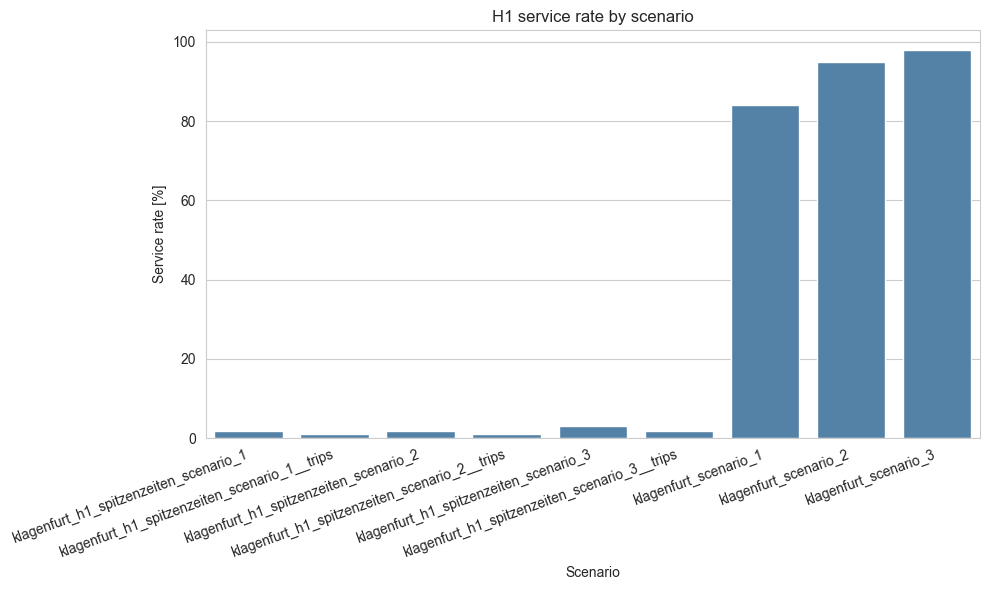

In [6]:
# H1 (Use Case 1) results
h1_results_dir = REPO_ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "results"
h1_df = load_case_results(h1_results_dir)

if h1_df.empty:
    print("No H1 results found in:", h1_results_dir)
else:
    h1_df = h1_df.sort_values("scenario")
    h1_df["avg_wait_min"] = h1_df["avg_wait_s"] / 60
    h1_df["median_wait_min"] = h1_df["median_wait_s"] / 60
    h1_df["p90_wait_min"] = h1_df["p90_wait_s"] / 60
    display_cols = [
        "scenario",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
    ]
    display(h1_df[display_cols])

    ax = sns.barplot(data=h1_df, x="scenario", y="service_rate_pct", color="steelblue")
    ax.set_title("H1 service rate by scenario")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

## UC2 results (baseline vs trips)

Scenarios include baseline, phone_support, simple_ui, full_support, students_15_20, and students_21_30. Trips results are suffixed with `__trips`.

,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,baseline,baseline,1.428571,1.900000,2.00,2.3,2.520833,5.0
1,baseline,trips,4.687500,3.000000,3.00,3.8,1.878462,3.0
2,full_support,baseline,1.714286,3.250000,2.25,5.5,4.632800,6.0
3,full_support,trips,4.687500,3.000000,3.00,3.8,1.753462,3.0
4,phone_support,baseline,1.428571,1.900000,2.00,2.3,2.465278,5.0
5,phone_support,trips,4.687500,3.000000,3.00,3.8,1.836795,3.0
6,simple_ui,baseline,1.428571,2.500000,2.00,3.4,3.438355,5.0
7,simple_ui,trips,4.687500,3.000000,3.00,3.8,1.836795,3.0
8,students_15_20,baseline,2.000000,3.571429,2.50,6.2,5.801117,7.0
9,students_15_20,trips,4.687500,3.000000,3.00,3.8,1.690962,3.0


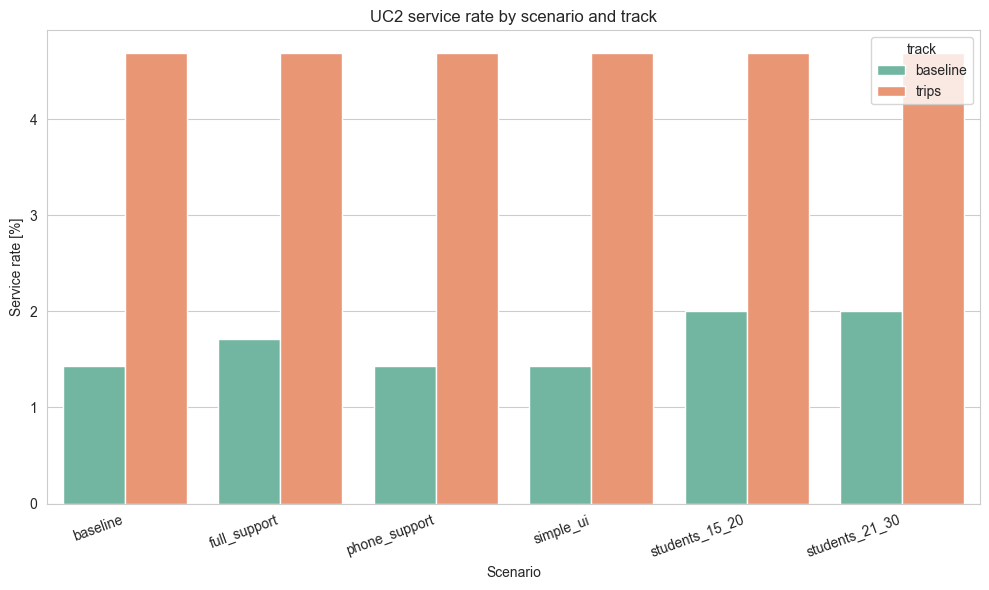

In [7]:
uc2_results_dir = REPO_ROOT / "studies" / "uc2_age_based" / "results"
uc2_df = load_case_results(uc2_results_dir)

if uc2_df.empty:
    print("No UC2 results found in:", uc2_results_dir)
else:
    uc2_df["track"] = np.where(uc2_df["scenario"].str.endswith("__trips"), "trips", "baseline")
    uc2_df["scenario_base"] = uc2_df["scenario"].str.replace("__trips", "", regex=False)
    uc2_df["avg_wait_min"] = uc2_df["avg_wait_s"] / 60
    uc2_df["median_wait_min"] = uc2_df["median_wait_s"] / 60
    uc2_df["p90_wait_min"] = uc2_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
    ]
    display(uc2_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=uc2_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("UC2 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

## UC3 results (baseline vs trips)

Scenarios include baseline, mixed_20, mixed_30, mixed_50. Trips results are suffixed with `__trips`.

,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users
0,baseline,trips,4.6875,3.0,3.0,3.8,1.815962,3.0
1,mixed_20,trips,4.6875,3.0,3.0,3.8,1.815962,3.0
2,mixed_30,trips,4.6875,3.0,3.0,3.8,1.815962,3.0
3,mixed_50,trips,4.6875,3.0,3.0,3.8,1.815962,3.0


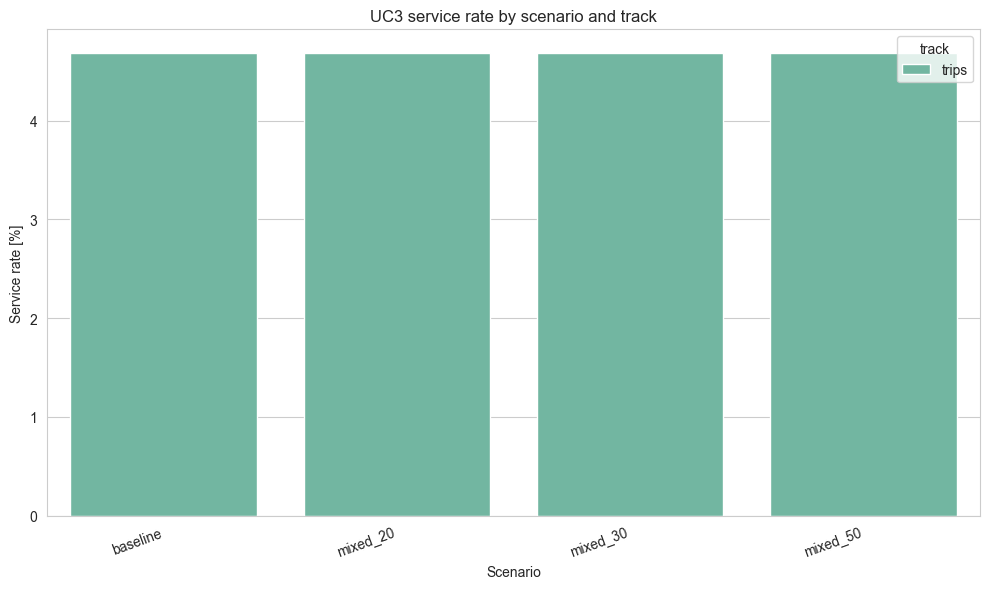

In [8]:
uc3_results_dir = REPO_ROOT / "studies" / "uc3_accessibility" / "results"
uc3_df = load_case_results(uc3_results_dir)

if uc3_df.empty:
    print("No UC3 results found in:", uc3_results_dir)
else:
    uc3_df["track"] = np.where(uc3_df["scenario"].str.endswith("__trips"), "trips", "baseline")
    uc3_df["scenario_base"] = uc3_df["scenario"].str.replace("__trips", "", regex=False)
    uc3_df["avg_wait_min"] = uc3_df["avg_wait_s"] / 60
    uc3_df["median_wait_min"] = uc3_df["median_wait_s"] / 60
    uc3_df["p90_wait_min"] = uc3_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
    ]
    display(uc3_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=uc3_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("UC3 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()